# One program, three engines

LazyQC lets you *describe* a batch of expectation values first and *run* it later.
Between the two steps a planner looks at the whole batch and decides how much
simulation work is really needed.

In this notebook we take one small program and evaluate it three ways:

1. **LazyQC**: plan the batch, then `collect()` it on Qulacs;
2. **Qulacs by hand**: one full statevector, every observable read from it;
3. **quimb by hand**: a tensor network contracted for each observable.

Along the way you will see what the planner decided and why, check that all three
engines agree with the exact answer, and compare what each one costs.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import math

import matplotlib.pyplot as plt
import quimb as qu
import quimb.tensor as qtn
import qulacs

from lazyqc import Program, plan_all
from lazyqc.backends.tensor import QuimbBackend
from nbtools import label, table, timed


def tidy(ax):
    """Light styling shared by the charts below."""
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

## The program: two entangled pairs, four questions

Each pair gets an $RY(\theta)$ rotation followed by a CX, which prepares
$\cos(\theta/2)\,|00\rangle + \sin(\theta/2)\,|11\rangle$. Pair A (qubits 0 and 1)
uses $\theta = 0.4$ and pair B (qubits 2 and 3) uses $\theta = 0.8$.

We ask four questions: $\langle Z_0\rangle$, $\langle Z_1\rangle$ and
$\langle X_0X_1\rangle$ on pair A, and $\langle Z_2Z_3\rangle$ on pair B. For this
state they can be worked out by hand: $\langle Z_0\rangle = \langle Z_1\rangle = \cos\theta$,
$\langle X_0X_1\rangle = \sin\theta$, and $\langle Z_2Z_3\rangle = 1$ because the two
qubits of a pair always agree in the $Z$ basis. That gives every engine an exact
reference.

In [2]:
program = Program(4).ry(0, 0.4).cx(0, 1).ry(2, 0.8).cx(2, 3)
observables = [{0: "Z"}, {1: "Z"}, {0: "X", 1: "X"}, {2: "Z", 3: "Z"}]
requests = [program.expectation(obs) for obs in observables]  # nothing is simulated yet
exact = [math.cos(0.4), math.cos(0.4), math.sin(0.4), 1.0]

table(
    [(i, label(obs), value) for i, (obs, value) in enumerate(zip(observables, exact))],
    ["request", "observable", "exact value"],
    digits=6,
)

| request | observable | exact value |
|---|---|---|
| 0 | Z0 | 0.921061 |
| 1 | Z1 | 0.921061 |
| 2 | X0 X1 | 0.389418 |
| 3 | Z2 Z3 | 1.00000 |

## Path A: the LazyQC planner

`program.expectation(...)` only recorded a question. `plan_all` now looks at the four
questions together. Planning is purely classical: it builds candidate plans, scores
them and picks one without allocating a single quantum state. The candidates are:

- **full**: one 4-qubit state for the whole program, every output read from it
  (what a direct simulator does);
- **separate**: one small simulation per question, restricted to the gates that can
  affect it (its *causal cone*);
- **grouped**: one simulation per distinct cone, shared by every question that needs
  that same cone.

In [3]:
plan = plan_all(requests)  # strategy="auto" keeps the candidate with the lowest work score
info = plan.explain()

table(
    [
        (
            alt["candidate"] + (" ✔" if alt["candidate"] == info["selected_candidate"] else ""),
            alt["evolutions"],
            alt["max_state_qubits"],
            alt["estimated_state_bytes"],
            alt["score"],
        )
        for alt in info["alternatives"]
    ],
    ["candidate", "state evolutions", "largest state (qubits)", "state memory (bytes)", "work score"],
)

| candidate | state evolutions | largest state (qubits) | state memory (bytes) | work score |
|---|---|---|---|---|
| full | 1 | 4 | 256 | 144 |
| separate | 4 | 2 | 64 | 64 |
| grouped ✔ | 2 | 2 | 64 | 40 |

The work score estimates gate work; it is not a time (`info["score_units"]` says so).
**grouped** wins because pair A's three questions share one 2-qubit simulation and
pair B gets its own. These are the groups the planner formed:

In [4]:
table(
    [
        (
            ", ".join(label(observables[i]) for i in group["request_indices"]),
            ", ".join(f"q{q}" for q in group["logical_to_local"]),
            group["gate_count"],
        )
        for group in info["groups"]
    ],
    ["questions answered", "qubits simulated", "gates"],
)

| questions answered | qubits simulated | gates |
|---|---|---|
| Z0, Z1, X0 X1 | q0, q1 | 2 |
| Z2 Z3 | q2, q3 | 2 |

### Where the score comes from

For each task $g$ with $m_g$ qubits, $|C_g|$ gates and $|\mathcal{G}_g|$ outputs, the
score adds up

$$W=\sum_g 2^{m_g}\,\bigl(1+|C_g|+|\mathcal{G}_g|\bigr),$$

roughly "amplitudes times (gates plus outputs)". The planner's numbers can be checked
by hand:

In [5]:
grouped_score = sum(2 ** g["state_qubits"] * (1 + g["gate_count"] + len(g["request_indices"])) for g in info["groups"])
full_score = 2**program.n_qubits * (1 + len(program.resolved_operations()) + len(requests))
scores = {alt["candidate"]: alt["score"] for alt in info["alternatives"]}
print(f"grouped: {grouped_score} by hand, {scores['grouped']} from the planner")
print(f"full:    {full_score} by hand, {scores['full']} from the planner")

grouped: 40 by hand, 40 from the planner
full:    144 by hand, 144 from the planner


Only now, at `collect()`, does LazyQC run Qulacs:

In [6]:
result = plan.collect()
stats = result.stats
table(
    [(label(obs), value, abs(value - ref)) for obs, value, ref in zip(observables, result.values, exact)],
    ["observable", "LazyQC value", "error vs exact"],
    digits=6,
)
print(f"{stats.evolutions} state evolutions, largest state {stats.max_state_qubits} qubits "
      f"({stats.estimated_state_bytes} bytes)")

| observable | LazyQC value | error vs exact |
|---|---|---|
| Z0 | 0.921061 | 0 |
| Z1 | 0.921061 | 0 |
| X0 X1 | 0.389418 | 5.6e-17 |
| Z2 Z3 | 1.00000 | 0 |

2 state evolutions, largest state 2 qubits (64 bytes)


## Path B: Qulacs by hand

The direct approach: lower the program to a Qulacs circuit, evolve one full 4-qubit
state and read every observable from it.

One detail is easy to get wrong. Qulacs defines rotations as $\exp(+i\theta P/2)$,
while LazyQC (like most textbooks) uses $\exp(-i\theta P/2)$, so every angle must
change sign on the way down. LazyQC's own Qulacs backend does this conversion for you.

In [7]:
def run_qulacs(program, observables):
    n = program.n_qubits
    circuit = qulacs.QuantumCircuit(n)
    for gate in program.resolved_operations():
        if gate.name == "CX":
            circuit.add_CNOT_gate(*gate.qubits)
        elif gate.angle is None:  # H, X, Y, Z
            getattr(circuit, f"add_{gate.name}_gate")(*gate.qubits)
        else:  # RX, RY, RZ: flip the sign of the angle
            getattr(circuit, f"add_{gate.name}_gate")(*gate.qubits, -gate.angle)
    state = qulacs.QuantumState(n)  # starts in |0...0>
    circuit.update_quantum_state(state)
    values = []
    for obs in observables:
        observable = qulacs.Observable(n)
        observable.add_operator(1.0, " ".join(f"{p} {q}" for q, p in sorted(obs.items())))
        values.append(observable.get_expectation_value(state))
    return tuple(values)


qulacs_values = run_qulacs(program, observables)

## Path C: quimb by hand

quimb turns the circuit into a tensor network. `local_expectation` contracts only the
part of the network that can influence the requested qubits (quimb's own light-cone
simplification), so the full statevector is never built. quimb uses the same rotation
convention as LazyQC, so the angles go in unchanged.

In [8]:
def run_quimb(program, observables):
    circuit = qtn.Circuit(program.n_qubits)
    for gate in program.resolved_operations():
        angle = () if gate.angle is None else (gate.angle,)
        circuit.apply_gate(gate.name, *angle, *gate.qubits)
    values = []
    for obs in observables:
        where = tuple(sorted(obs))
        operator = qu.kron(*(qu.pauli(obs[q]) for q in where))
        values.append(float(circuit.local_expectation(operator, where).real))
    return tuple(values)


quimb_values = run_quimb(program, observables)

## Bonus: plan once, pick the engine at `collect()`

The plan does not depend on Qulacs. Passing another backend to `collect()` runs the
same two small simulations as quimb tensor networks. `collect` can also split a plan
across two backends, sending only tasks of at least `wide_from` qubits to a
`wide_backend` such as a GPU; notebook 03 shows why that matters.

In [9]:
backend_values = plan.collect(backend=QuimbBackend()).values

## Do they agree, and what does each cost?

Each engine runs five times. LazyQC is timed from planning to values, since a fresh
batch would need both.

| engine | max error vs exact | median time (ms) |
|---|---|---|
| LazyQC on Qulacs | 5.6e-17 | 0.168 |
| LazyQC on quimb | 8.9e-16 | 9.38 |
| Qulacs by hand | 1.1e-16 | 0.0331 |
| quimb by hand | 8.9e-16 | 8.48 |

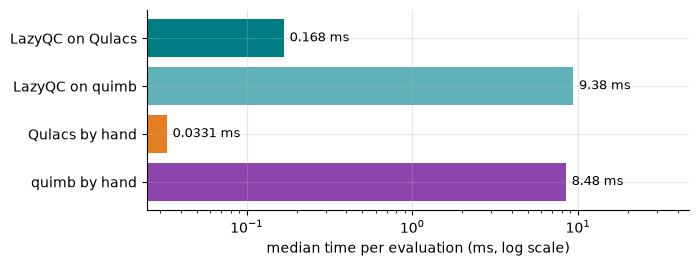

In [10]:
engines = {
    "LazyQC on Qulacs": lambda: plan_all(requests).collect().values,
    "LazyQC on quimb": lambda: plan_all(requests).collect(backend=QuimbBackend()).values,
    "Qulacs by hand": lambda: run_qulacs(program, observables),
    "quimb by hand": lambda: run_quimb(program, observables),
}
rows = []
for name, run in engines.items():
    values, ms = timed(run)
    rows.append((name, max(abs(v - ref) for v, ref in zip(values, exact)), ms))
table(rows, ["engine", "max error vs exact", "median time (ms)"])

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh([r[0] for r in rows], [r[2] for r in rows], color=["#007D84", "#5FB3B8", "#E67E22", "#8E44AD"])
ax.bar_label(bars, labels=[f"{r[2]:.3g} ms" for r in rows], padding=4, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(right=5 * max(r[2] for r in rows))
ax.set_xlabel("median time per evaluation (ms, log scale)")
ax.invert_yaxis()
tidy(ax)
plt.show()

## What to take away

- Every engine matches the exact values to about $10^{-16}$. Planning changes *how
  much* is simulated, never *what* is computed.
- On a 4-qubit circuit direct Qulacs is the fastest. One tiny state is so cheap that
  the planner's bookkeeping (building and scoring candidates, lowering several small
  circuits) costs more than it saves. The planner pays off once the full state is
  large compared with the cones; notebook 02 measures where.
- quimb pays for tensor bookkeeping and contraction-path search on every call. It
  shines where a dense state would not fit in memory but the networks stay narrow,
  far beyond this example.
- The planner's decision can be inspected before anything runs (`explain()`), and
  the same plan runs on different backends.

## Try it yourself

- Add a question that spans both pairs, such as `{1: "Z", 2: "Z"}`. What happens to
  the groups and to the largest state?
- Change the angles and check the values against $\cos\theta$ and $\sin\theta$.